# Does a promotional email pay off? An A/B test on the Hillstrom dataset

In 2008 Kevin Hillstrom (MineThatData) ran an email experiment on 64,000 customers of a retailer that sells
both men's and women's merchandise. Every customer had bought something in the previous twelve months.
They were split at random into three groups of roughly equal size:

- Mens E-Mail: received an email featuring men's merchandise
- Womens E-Mail: received an email featuring women's merchandise
- No E-Mail: received nothing (the control group)

For two weeks after the send, the retailer recorded whether each customer visited the website,
whether they bought something, and how much they spent.

This notebook answers two questions the marketing team would care about:

1. Does sending an email lead to more purchases than sending nothing?
2. If we only send one version, which one should it be?

I treat purchase conversion as the primary metric because it is the outcome the campaign exists to change.
Spend and visits are secondary metrics.

**Short answer:** both emails beat no email, and the Mens email beats the Womens email on every metric.
The details, with confidence intervals and caveats, are below.

## 1. Setup

In [1]:
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

GROUPS = ["Control", "Womens", "Mens"]
COLORS = {"Control": "#8a8f98", "Womens": "#c2557a", "Mens": "#2f6fb0"}
ALPHA = 0.05
RNG = np.random.default_rng(2008)

## 2. Load the data

The original download link on minethatdata.com is not always reachable, so the cell below falls back to a
public mirror. The CSV is not committed to the repository; it is fetched on first run.

In [2]:
DATA_DIR = Path("../data")
DATA_FILE = DATA_DIR / "hillstrom.csv"
SOURCES = [
    "http://www.minethatdata.com/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv",
    "https://hillstorm1.s3.us-east-2.amazonaws.com/hillstorm_no_indices.csv.gz",
]

if not DATA_FILE.exists():
    DATA_DIR.mkdir(exist_ok=True)
    for url in SOURCES:
        try:
            pd.read_csv(url).to_csv(DATA_FILE, index=False)
            print(f"Downloaded from {url}")
            break
        except Exception as err:
            print(f"Could not read {url}: {err}")
    else:
        raise RuntimeError("No source worked. Download the CSV by hand into data/hillstrom.csv.")

raw = pd.read_csv(DATA_FILE)
print(raw.shape)
raw.head()

(64000, 12)


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.4400,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0000
1,6,3) $200 - $350,329.0800,1,1,Rural,1,Web,No E-Mail,0,0,0.0000
2,7,2) $100 - $200,180.6500,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0000
3,9,5) $500 - $750,675.8300,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0000
4,2,1) $0 - $100,45.3400,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0000


| Column | Meaning |
|---|---|
| `recency` | Months since last purchase (1 to 12) |
| `history` | Dollars spent in the past year; `history_segment` is the same value in bins |
| `mens`, `womens` | 1 if the customer bought men's / women's merchandise in the past year |
| `zip_code` | Urban, Suburban or Rural (spelled "Surburban" in the source) |
| `newbie` | 1 if the customer was acquired in the past twelve months |
| `channel` | Channels the customer bought from last year: Phone, Web or Multichannel |
| `segment` | The randomly assigned group |
| `visit`, `conversion`, `spend` | Outcomes in the two weeks after the email |

I rename the groups to shorter labels and fix the "Surburban" typo.

In [3]:
df = raw.copy()
df["group"] = pd.Categorical(
    df["segment"].map({"No E-Mail": "Control", "Womens E-Mail": "Womens", "Mens E-Mail": "Mens"}),
    categories=GROUPS,
)
df["zip_code"] = df["zip_code"].replace("Surburban", "Suburban")

print("Missing values:", int(df.isna().sum().sum()))
print("Rows identical on every column:", int(df.duplicated().sum()))
df.describe().T

Missing values: 0
Rows identical on every column: 6562


,count,mean,std,min,25%,50%,75%,max
recency,"64,000.0000",5.7637,3.5076,1.0000,2.0000,6.0000,9.0000,12.0000
history,"64,000.0000",242.0857,256.1586,29.9900,64.6600,158.1100,325.6575,"3,345.9300"
mens,"64,000.0000",0.5510,0.4974,0.0000,0.0000,1.0000,1.0000,1.0000
womens,"64,000.0000",0.5497,0.4975,0.0000,0.0000,1.0000,1.0000,1.0000
newbie,"64,000.0000",0.5022,0.5000,0.0000,0.0000,1.0000,1.0000,1.0000
visit,"64,000.0000",0.1468,0.3539,0.0000,0.0000,0.0000,0.0000,1.0000
conversion,"64,000.0000",0.0090,0.0946,0.0000,0.0000,0.0000,0.0000,1.0000
spend,"64,000.0000",1.0509,15.0364,0.0000,0.0000,0.0000,0.0000,499.0000


There are no missing values. About 6,500 rows are identical on every column, but the dataset has no customer
ID, and most columns are coarse (binary flags, a 1 to 12 month counter, and outcomes that are almost always 0).
Two different customers can easily share a row. Without an ID there is no way to tell real duplicates from
look-alikes, so I keep every row.

## 3. Sanity checks

A test result is only as good as the randomisation behind it. Before looking at outcomes I check two things.

### 3.1 Sample ratio mismatch (SRM)

The design called for a one-third split. If the observed counts are far from that, something went wrong
in assignment or logging, and the outcome comparison cannot be trusted.

In [4]:
counts = df["group"].value_counts().reindex(GROUPS)
srm = stats.chisquare(counts)
print(counts.to_string())
print(f"\nChi-square = {srm.statistic:.3f}, p = {srm.pvalue:.3f}")

group
Control    21306
Womens     21387
Mens       21307

Chi-square = 0.203, p = 0.904


p = 0.90, so the split is consistent with one third per group. The usual alarm threshold for SRM is p < 0.001.

### 3.2 Covariate balance

Randomisation should also make the groups look alike on everything measured before the email went out.
I report the standardised mean difference (SMD) of each email group against control. An absolute SMD under 0.1
is the common rule of thumb for good balance.

In [5]:
covariates = pd.get_dummies(
    df[["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]],
    columns=["zip_code", "channel"],
    dtype=float,
)


def smd(x, y):
    pooled_sd = np.sqrt((x.var() + y.var()) / 2)
    return (x.mean() - y.mean()) / pooled_sd


control_rows = df["group"] == "Control"
balance = pd.DataFrame({
    g: [smd(covariates.loc[df["group"] == g, c], covariates.loc[control_rows, c]) for c in covariates]
    for g in ["Womens", "Mens"]
}, index=covariates.columns)
balance["max_abs_smd"] = balance.abs().max(axis=1)
balance.sort_values("max_abs_smd", ascending=False)

,Womens,Mens,max_abs_smd
zip_code_Rural,0.0040,0.0137,0.0137
zip_code_Suburban,-0.0011,-0.0117,0.0117
channel_Web,-0.0051,0.0110,0.0110
mens,-0.0086,-0.0046,0.0086
channel_Phone,0.0086,-0.0083,0.0086
history,0.0065,0.0076,0.0076
womens,0.0049,0.0076,0.0076
recency,0.0052,0.0068,0.0068
channel_Multichannel,-0.0053,-0.0042,0.0053
newbie,0.0026,-0.0009,0.0026


The largest absolute SMD is well under 0.1. Chi-square tests on the categorical columns and Kruskal-Wallis tests
on `recency` and `history` (not shown) also find nothing. The groups are comparable, so differences in outcomes
can be attributed to the email.

## 4. First look at the outcomes

In [6]:
summary = df.groupby("group", observed=True).agg(
    customers=("visit", "size"),
    visit_rate=("visit", "mean"),
    conversion_rate=("conversion", "mean"),
    spend_per_customer=("spend", "mean"),
)
summary["spend_per_buyer"] = (
    df[df["conversion"] == 1].groupby("group", observed=True)["spend"].mean()
)
summary

,customers,visit_rate,conversion_rate,spend_per_customer,spend_per_buyer
group,,,,,
Control,21306,0.1062,0.0057,0.6528,114.0027
Womens,21387,0.1514,0.0088,1.0772,121.8948
Mens,21307,0.1828,0.0125,1.4226,113.5269


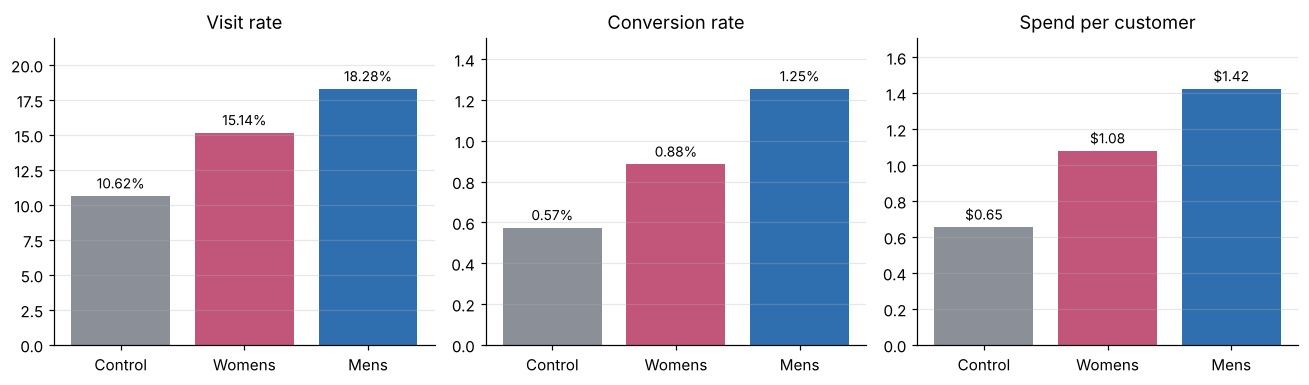

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
metrics = [
    ("visit_rate", "Visit rate", 100, "%"),
    ("conversion_rate", "Conversion rate", 100, "%"),
    ("spend_per_customer", "Spend per customer", 1, "$"),
]
for ax, (col, title, scale, unit) in zip(axes, metrics):
    values = summary[col] * scale
    bars = ax.bar(GROUPS, values, color=[COLORS[g] for g in GROUPS])
    labels = [f"{v:.2f}%" if unit == "%" else f"${v:.2f}" for v in values]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=9)
    ax.set_title(title)
    ax.set_ylim(0, values.max() * 1.2)
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Both email groups are ahead of control, and Mens is ahead of Womens. Conversion is rare: under 1.3% in every group.
That matters for the statistics, because small rates mean wide confidence intervals.

Spend needs care. Almost every customer spent $0, so the mean is pulled up by a few buyers.

Share of customers with spend = 0: 99.10%


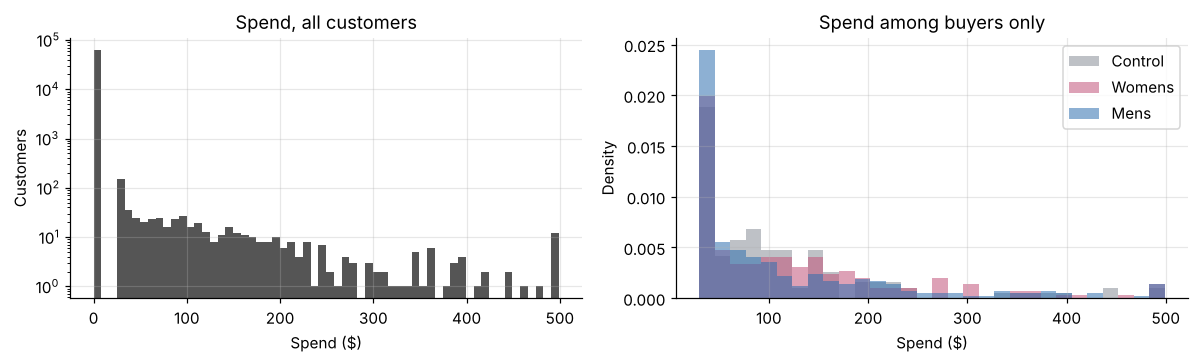

In [8]:
print(f"Share of customers with spend = 0: {(df['spend'] == 0).mean():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(df["spend"], bins=60, color="#555")
axes[0].set(title="Spend, all customers", xlabel="Spend ($)", ylabel="Customers", yscale="log")

buyers = df[df["conversion"] == 1]
for g in GROUPS:
    axes[1].hist(buyers.loc[buyers["group"] == g, "spend"], bins=30, alpha=0.55, color=COLORS[g], label=g, density=True)
axes[1].set(title="Spend among buyers only", xlabel="Spend ($)", ylabel="Density")
axes[1].legend()
plt.tight_layout()
plt.show()

Among buyers, the spend distributions overlap almost completely. That hints that the emails work mainly by
getting more people to buy, not by making each buyer spend more. I come back to why spend among buyers is
not a valid causal comparison in section 6.3.

## 5. Was the sample big enough?

With about 21,300 customers per group, what is the smallest lift the test could reliably detect?
I use 80% power and alpha = 0.05 / 3, because three pairwise comparisons share one error budget.

In [9]:
n_per_group = int(counts.min())
alpha_adj = ALPHA / 3
power_calc = NormalIndPower()


def minimum_detectable_rate(base_rate):
    def gap(p2):
        es = proportion_effectsize(p2, base_rate)
        return power_calc.power(es, nobs1=n_per_group, alpha=alpha_adj) - 0.8
    from scipy.optimize import brentq
    return brentq(gap, base_rate + 1e-6, 0.99)


for metric in ["visit", "conversion"]:
    base = df.loc[control_rows, metric].mean()
    target = minimum_detectable_rate(base)
    print(f"{metric:<11} control {base:.4f}  detectable {target:.4f}  ({target / base - 1:+.0%} relative)")

visit       control 0.1062  detectable 0.1160  (+9% relative)
conversion  control 0.0057  detectable 0.0083  (+46% relative)


For conversion the test can reliably detect a lift of about 46% relative to control. Smaller real effects
could be missed. Keep this in mind when reading the Mens versus Womens comparison, which sits close to that line.

## 6. Results

### 6.1 Primary metric: conversion

Step one is an omnibus chi-square test on the 3 x 2 table (group by converted or not). It asks whether the three
conversion rates are all equal. Step two compares each pair with a two-proportion z-test, and adjusts the
three p-values with the Holm method so the chance of any false positive stays at 5%.

In [10]:
PAIRS = [("Mens", "Control"), ("Womens", "Control"), ("Mens", "Womens")]


def compare_proportions(metric):
    rows = []
    for treat, base in PAIRS:
        x_t = df.loc[df["group"] == treat, metric]
        x_b = df.loc[df["group"] == base, metric]
        p_t, p_b = x_t.mean(), x_b.mean()
        n_t, n_b = len(x_t), len(x_b)

        p_pool = (x_t.sum() + x_b.sum()) / (n_t + n_b)
        se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n_t + 1 / n_b))
        z = (p_t - p_b) / se_pool

        # The CI uses the unpooled SE because it describes the difference, not the null.
        se_diff = np.sqrt(p_t * (1 - p_t) / n_t + p_b * (1 - p_b) / n_b)
        diff = p_t - p_b
        rows.append({
            "comparison": f"{treat} vs {base}",
            "rate_treat": p_t,
            "rate_base": p_b,
            "abs_diff": diff,
            "ci_low": diff - 1.96 * se_diff,
            "ci_high": diff + 1.96 * se_diff,
            "rel_lift": diff / p_b,
            "z": z,
            "p_raw": 2 * stats.norm.sf(abs(z)),
        })
    out = pd.DataFrame(rows).set_index("comparison")
    out["p_holm"] = multipletests(out["p_raw"], method="holm")[1]
    out["significant"] = out["p_holm"] < ALPHA
    return out


chi2, p_omni, _, _ = stats.chi2_contingency(pd.crosstab(df["group"], df["conversion"]))
print(f"Omnibus chi-square: chi2 = {chi2:.1f}, p = {p_omni:.1e}\n")
conversion_results = compare_proportions("conversion")
conversion_results

Omnibus chi-square: chi2 = 55.3, p = 1.0e-12



,rate_treat,rate_base,abs_diff,ci_low,ci_high,rel_lift,z,p_raw,p_holm,significant
comparison,,,,,,,,,,
Mens vs Control,0.0125,0.0057,0.0068,0.0050,0.0086,1.1884,7.3851,0.0000,0.0000,True
Womens vs Control,0.0088,0.0057,0.0031,0.0015,0.0047,0.5433,3.7796,0.0002,0.0003,True
Mens vs Womens,0.0125,0.0088,0.0037,0.0017,0.0056,0.4180,3.7126,0.0002,0.0003,True


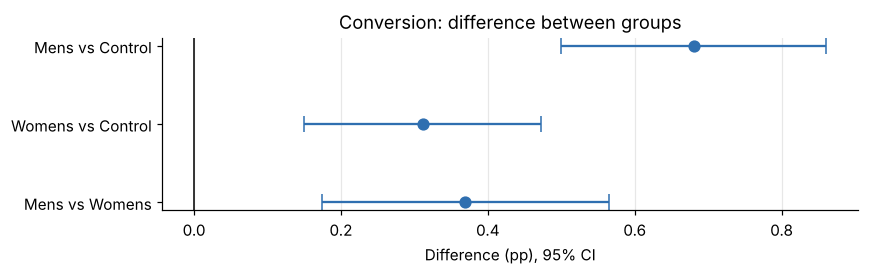

In [11]:
def forest_plot(results, title, scale=100, unit="pp"):
    fig, ax = plt.subplots(figsize=(8, 2.6))
    y = np.arange(len(results))[::-1]
    diff = results["abs_diff"] * scale
    err = [diff - results["ci_low"] * scale, results["ci_high"] * scale - diff]
    ax.errorbar(diff, y, xerr=err, fmt="o", color="#2f6fb0", capsize=5, ms=7)
    ax.axvline(0, color="black", lw=1)
    ax.set_yticks(y, results.index)
    ax.set_xlabel(f"Difference ({unit}), 95% CI")
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()


forest_plot(conversion_results, "Conversion: difference between groups")

All three comparisons are significant after the Holm adjustment, and no interval crosses zero.

- Mens vs Control: conversion goes from 0.57% to 1.25%, a gain of 0.68 percentage points (95% CI 0.50 to 0.86).
  In relative terms the Mens email roughly doubles conversion.
- Womens vs Control: 0.57% to 0.88%, a gain of 0.31 points (CI 0.15 to 0.47), about +54%.
- Mens vs Womens: Mens is 0.37 points higher (CI 0.17 to 0.56).

The power check said a Mens vs Womens gap might be hard to detect. The observed gap turned out large enough to clear it.

### 6.2 Secondary metric: visits

Same method, same story, with much smaller p-values because visits are about fifteen times more common than purchases.

In [12]:
visit_results = compare_proportions("visit")
visit_results

,rate_treat,rate_base,abs_diff,ci_low,ci_high,rel_lift,z,p_raw,p_holm,significant
comparison,,,,,,,,,,
Mens vs Control,0.1828,0.1062,0.0766,0.0700,0.0832,0.7214,22.4860,0.0000,0.0000,True
Womens vs Control,0.1514,0.1062,0.0452,0.0389,0.0516,0.4261,13.9492,0.0000,0.0000,True
Mens vs Womens,0.1828,0.1514,0.0314,0.0243,0.0384,0.2071,8.6846,0.0000,0.0000,True


### 6.3 Secondary metric: spend per customer

Spend per customer is what finance cares about, and it includes the customers who spent nothing.
I use three tests because each one covers a weakness of the others:

- Welch's t-test compares means without assuming equal variances. With 21,000 customers per group the
  sampling distribution of the mean is close to normal even though spend itself is very skewed.
- A bootstrap confidence interval makes no distribution assumption at all. If it agrees with Welch,
  the skew is not distorting the result.
- The Mann-Whitney U test compares whole distributions. With 99% zeros it mostly picks up the
  difference in how many people bought, so I treat it as a robustness check only.

In [13]:
def bootstrap_mean_diff(x, y, n_boot=4000):
    x, y = np.asarray(x), np.asarray(y)
    idx_x = RNG.integers(0, len(x), size=(n_boot, len(x)))
    idx_y = RNG.integers(0, len(y), size=(n_boot, len(y)))
    return x[idx_x].mean(axis=1) - y[idx_y].mean(axis=1)


spend_rows, boot_draws = [], {}
for treat, base in PAIRS:
    x_t = df.loc[df["group"] == treat, "spend"]
    x_b = df.loc[df["group"] == base, "spend"]
    welch = stats.ttest_ind(x_t, x_b, equal_var=False)
    ci = welch.confidence_interval()
    draws = bootstrap_mean_diff(x_t, x_b)
    boot_draws[f"{treat} vs {base}"] = draws
    spend_rows.append({
        "comparison": f"{treat} vs {base}",
        "mean_treat": x_t.mean(),
        "mean_base": x_b.mean(),
        "abs_diff": x_t.mean() - x_b.mean(),
        "welch_ci_low": ci.low,
        "welch_ci_high": ci.high,
        "boot_ci_low": np.quantile(draws, 0.025),
        "boot_ci_high": np.quantile(draws, 0.975),
        "p_welch": welch.pvalue,
        "p_mannwhitney": stats.mannwhitneyu(x_t, x_b).pvalue,
    })

spend_results = pd.DataFrame(spend_rows).set_index("comparison")
spend_results["p_welch_holm"] = multipletests(spend_results["p_welch"], method="holm")[1]
spend_results

,mean_treat,mean_base,abs_diff,welch_ci_low,welch_ci_high,boot_ci_low,boot_ci_high,p_welch,p_mannwhitney,p_welch_holm
comparison,,,,,,,,,,
Mens vs Control,1.4226,0.6528,0.7698,0.4851,1.0545,0.4845,1.0517,0.0000,0.0000,0.0000
Womens vs Control,1.0772,0.6528,0.4244,0.1690,0.6799,0.1714,0.6808,0.0011,0.0002,0.0023
Mens vs Womens,1.4226,1.0772,0.3454,0.0326,0.6583,0.0344,0.6706,0.0305,0.0002,0.0305


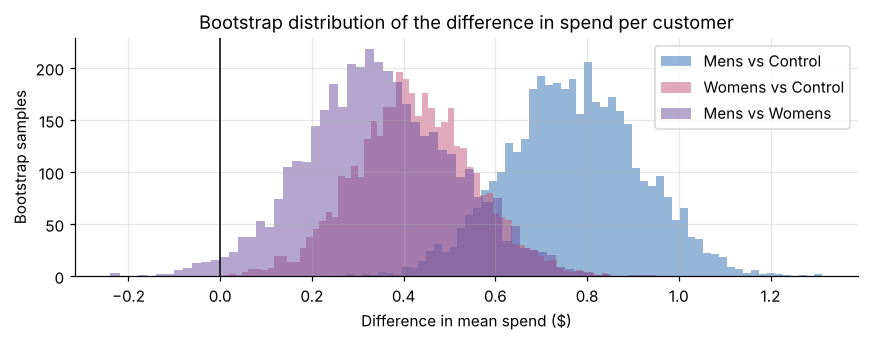

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for (label, draws), color in zip(boot_draws.items(), ["#2f6fb0", "#c2557a", "#6b4fa0"]):
    ax.hist(draws, bins=60, alpha=0.5, color=color, label=label)
ax.axvline(0, color="black", lw=1)
ax.set(title="Bootstrap distribution of the difference in spend per customer",
       xlabel="Difference in mean spend ($)", ylabel="Bootstrap samples")
ax.legend()
plt.tight_layout()
plt.show()

Welch and bootstrap intervals agree to within a few cents, so the skew is not a problem at this sample size.

- Mens adds about $0.77 per customer over control (CI roughly $0.49 to $1.05).
- Womens adds about $0.42 (CI roughly $0.17 to $0.68).
- Mens vs Womens: $0.35 in favour of Mens. The Holm-adjusted p-value is 0.03, so this one is significant but
  only just, and its interval runs from about $0.03 to $0.66.

**Why I do not compare spend among buyers only.** It is tempting to ask whether buyers in the email groups
spent more per order. But who becomes a buyer is itself affected by the email. If the email nudges marginal
customers into a small purchase, the average order among buyers can drop even though the email made money.
Conditioning on a post-treatment outcome breaks the randomisation, so that number is descriptive, not causal.

## 7. Regression adjustment

Adding pre-experiment customer data to a regression can shrink the standard error of the treatment effect,
because it explains some of the noise in the outcome. I fit a linear probability model for conversion and an
OLS model for spend, each with and without covariates, using heteroskedasticity-robust (HC1) standard errors.

In [15]:
COVARS = "recency + np.log(history) + mens + womens + newbie + C(zip_code) + C(channel)"
rows = []
for outcome in ["conversion", "spend"]:
    plain = smf.ols(f"{outcome} ~ C(group)", df).fit(cov_type="HC1")
    adjusted = smf.ols(f"{outcome} ~ C(group) + {COVARS}", df).fit(cov_type="HC1")
    for g in ["Womens", "Mens"]:
        term = f"C(group)[T.{g}]"
        rows.append({
            "outcome": outcome,
            "effect_vs_control": g,
            "estimate_plain": plain.params[term],
            "se_plain": plain.bse[term],
            "estimate_adjusted": adjusted.params[term],
            "se_adjusted": adjusted.bse[term],
            "se_reduction": 1 - adjusted.bse[term] / plain.bse[term],
        })
pd.DataFrame(rows).set_index(["outcome", "effect_vs_control"])

estimate_plain  se_plain  estimate_adjusted  \
outcome    effect_vs_control                                                
conversion Womens                     0.0031    0.0008             0.0031   
           Mens                       0.0068    0.0009             0.0068   
spend      Womens                     0.4244    0.1303             0.4276   
           Mens                       0.7698    0.1452             0.7688   

                              se_adjusted  se_reduction  
outcome    effect_vs_control                             
conversion Womens                  0.0008        0.0006  
           Mens                    0.0009        0.0010  
spend      Womens                  0.1304       -0.0005  
           Mens                    0.1451        0.0009

The estimates barely move, which is another sign the randomisation worked. The standard errors also barely
move: the reduction is well under 1%. The covariates in this dataset are weak predictors of whether someone buys
in a specific two-week window, so adjustment does not buy much precision here. It would help more with a
stronger pre-period signal, such as each customer's purchases in the two weeks before the test.
This is a useful negative result: the simple comparisons above are already as precise as this data allows.

## 8. Does the effect differ by customer type?

The overall result says Mens wins. But the retailer could send different emails to different customers,
so it is worth checking whether the effect depends on who receives it.

For each candidate segment I fit a logistic regression with and without a group-by-segment interaction and
compare them with a likelihood ratio test. A small p-value means the email effect differs across that segment.
I check four segments, so the p-values are Holm-adjusted. This part is exploratory: the experiment was not
designed around these segments.

In [16]:
df["tenure"] = np.where(df["newbie"] == 1, "New this year", "Returning")
df["buyer_type"] = np.select(
    [(df["mens"] == 1) & (df["womens"] == 1), df["mens"] == 1],
    ["Bought both", "Bought mens only"],
    default="Bought womens only",
)
SEGMENTS = ["buyer_type", "newbie", "channel", "zip_code"]

rows = []
for seg in SEGMENTS:
    full = smf.logit(f"conversion ~ C(group) * C({seg})", df).fit(disp=0)
    reduced = smf.logit(f"conversion ~ C(group) + C({seg})", df).fit(disp=0)
    lr = 2 * (full.llf - reduced.llf)
    dof = full.df_model - reduced.df_model
    rows.append({"segment": seg, "lr_stat": lr, "df": int(dof), "p_raw": stats.chi2.sf(lr, dof)})

interactions = pd.DataFrame(rows).set_index("segment")
interactions["p_holm"] = multipletests(interactions["p_raw"], method="holm")[1]
interactions

,lr_stat,df,p_raw,p_holm
segment,,,,
buyer_type,9.4974,4,0.0498,0.1494
newbie,10.4097,2,0.0055,0.0220
channel,1.7056,4,0.7897,1.0000
zip_code,2.9586,4,0.5648,1.0000


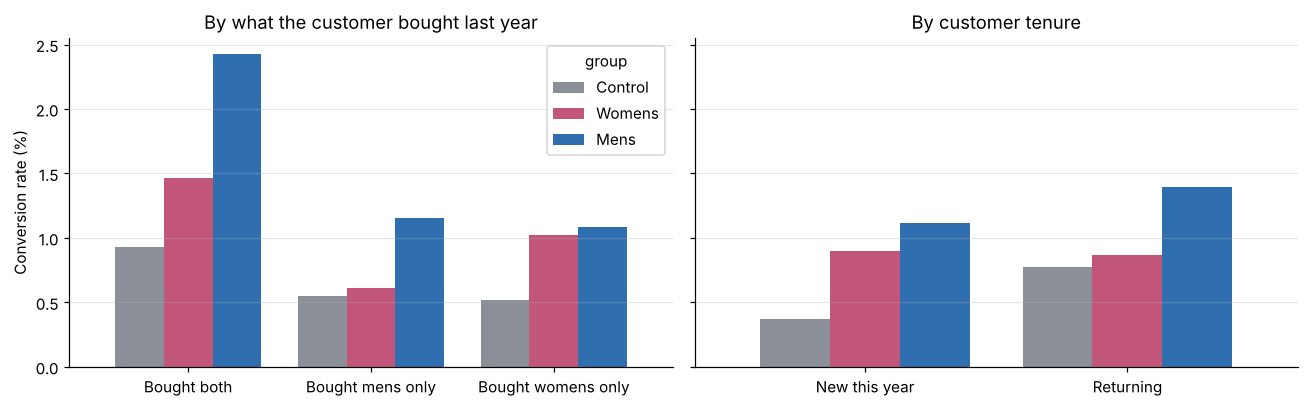

group,Control,Womens,Mens
buyer_type,,,
Bought both,0.0093,0.0146,0.0243
Bought mens only,0.0055,0.0061,0.0115
Bought womens only,0.0051,0.0103,0.0109


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, seg, title in [
    (axes[0], "buyer_type", "By what the customer bought last year"),
    (axes[1], "tenure", "By customer tenure"),
]:
    table = df.groupby([seg, "group"], observed=True)["conversion"].mean().unstack()[GROUPS] * 100
    table.plot.bar(ax=ax, color=[COLORS[g] for g in GROUPS], width=0.8, rot=0)
    ax.set(title=title, xlabel="", ylabel="Conversion rate (%)")
    ax.grid(axis="x", visible=False)
axes[1].get_legend().remove()
plt.tight_layout()
plt.show()

df.groupby(["buyer_type", "group"], observed=True)["conversion"].mean().unstack()[GROUPS]

Two patterns stand out.

**Tenure (newbie).** The interaction survives the Holm adjustment. New customers barely buy without an email
(0.37%), and both emails lift them a lot. For established customers the Womens email adds little on top of control.

**Purchase history (buyer_type).** The raw p-value is just under 0.05 but it does not survive the adjustment,
so treat it as a hint. The pattern is easy to explain, though. The Womens email works for customers who bought
women's items last year and does almost nothing for customers who only bought men's items (0.61% vs 0.55% control).
The Mens email lifts every group, including customers who only bought women's items.

Channel and zip code show no sign of different effects.

## 9. A Bayesian view

The frequentist tests answer "if the emails had no effect, how surprising is this data?". A marketing manager
usually wants a different answer: "how likely is it that Mens is really the better email, and what do I lose
if I pick it and I'm wrong?". A Bayesian model answers that directly.

For each group I model the conversion rate with a Beta-Binomial model. With a flat Beta(1, 1) prior, the
posterior after seeing *k* buyers out of *n* customers is Beta(1 + *k*, 1 + *n* - *k*). I draw 200,000 samples
from each posterior and compute:

- the probability that each group has the highest conversion rate
- the expected loss of choosing each group: the conversion we would give up, on average, if another group is actually better

In [18]:
n_draws = 200_000
posterior = {}
for g in GROUPS:
    x = df.loc[df["group"] == g, "conversion"]
    posterior[g] = RNG.beta(1 + x.sum(), 1 + len(x) - x.sum(), n_draws)

draws = np.column_stack([posterior[g] for g in GROUPS])
best = draws.max(axis=1)
bayes = pd.DataFrame({
    "posterior_mean": draws.mean(axis=0),
    "ci95_low": np.quantile(draws, 0.025, axis=0),
    "ci95_high": np.quantile(draws, 0.975, axis=0),
    "prob_best": np.bincount(draws.argmax(axis=1), minlength=3) / n_draws,
    "expected_loss_pp": (best[:, None] - draws).mean(axis=0) * 100,
}, index=GROUPS)

lift_mens_vs_womens = posterior["Mens"] / posterior["Womens"] - 1
print(f"P(Mens > Womens) = {(posterior['Mens'] > posterior['Womens']).mean():.4f}")
print(f"Relative lift of Mens over Womens, 95% credible interval: "
      f"{np.quantile(lift_mens_vs_womens, 0.025):+.0%} to {np.quantile(lift_mens_vs_womens, 0.975):+.0%}")
bayes

P(Mens > Womens) = 0.9999
Relative lift of Mens over Womens, 95% credible interval: +18% to +71%


,posterior_mean,ci95_low,ci95_high,prob_best,expected_loss_pp
Control,0.0058,0.0048,0.0068,0.0000,0.6804
Womens,0.0089,0.0077,0.0102,0.0001,0.3692
Mens,0.0126,0.0111,0.0141,0.9999,0.0000


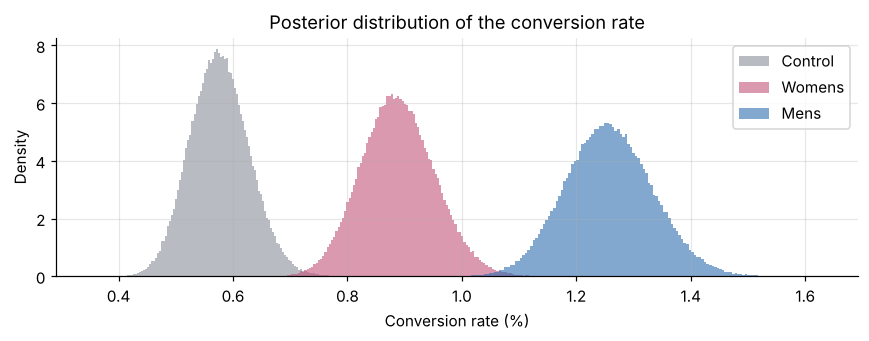

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for g in GROUPS:
    ax.hist(posterior[g] * 100, bins=150, density=True, alpha=0.6, color=COLORS[g], label=g)
ax.set(title="Posterior distribution of the conversion rate", xlabel="Conversion rate (%)", ylabel="Density")
ax.legend()
plt.tight_layout()
plt.show()

The posteriors barely overlap. The Bayesian and frequentist analyses agree: Mens is almost certainly the
best email, and the expected loss of choosing it is effectively zero.

## 10. What is it worth?

Spend per customer turns the result into money. Using the Welch estimates from section 6.3:

In [20]:
impact = spend_results.loc[["Mens vs Control", "Womens vs Control"], ["abs_diff", "welch_ci_low", "welch_ci_high"]] * 1000
impact.columns = ["extra_revenue_per_1000_emails", "ci_low", "ci_high"]
impact.round(0)

,extra_revenue_per_1000_emails,ci_low,ci_high
comparison,,,
Mens vs Control,770.0000,485.0000,"1,055.0000"
Womens vs Control,424.0000,169.0000,680.0000


Every 1,000 Mens emails bring in roughly $770 of extra revenue in the two weeks after the send
(95% CI about $490 to $1,050). The Womens email brings in about $420.

These are revenue figures, not profit. The dataset has no product margins or email costs. Email is cheap to send,
so the gain almost certainly covers the cost, but the profit number needs data the dataset does not have.

## 11. Recommendation

**Send the Mens email.** It beats both the Womens email and no email on conversion, visits and spend.
The randomisation checks pass, and the frequentist and Bayesian results agree.

If the team can target, the segment analysis suggests one test worth running next: send the Womens email
only to customers who bought women's items last year, and the Mens email to everyone else. The data hints this
could work, but the interaction was not significant after adjustment, so it needs its own experiment before
anyone acts on it.

### Limitations

- Outcomes cover two weeks. Long-term effects, such as unsubscribes or customers buying earlier than they would have anyway, are not measured.
- There are no guardrail metrics. A real campaign should also track unsubscribes and spam complaints.
- Revenue is not profit. Margins and send costs are unknown.
- The experiment ran in 2008 on one retailer's customers. The direction of the result may transfer; the exact sizes may not.
- The segment analysis is exploratory and was not pre-registered.